In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy.interpolate import interp1d, UnivariateSpline
from scipy.optimize import brentq


def uncoupled_smooth_sirv(t, y, params):
    """
    Uncoupled smooth SIRv system (epsilon = 0)
    y = [S, I, v]
    """
    S, I, v = y
    alpha = params['alpha']
    beta = params['beta']
    gamma = params['gamma']
    eta = params['eta']
    theta = params['theta']
    kappa = params['kappa']
    rho = params['rho']

    dS = alpha*(1 - S - I) - beta*S*(I) - eta*v*S
    dI = -gamma*I + beta*S*(I)
    dv = -v + 1/(1 + np.exp(-kappa*(beta*I - rho - theta*(1 - 2*v))))

    return [dS, dI, dv]


# =============================================================================
# COMPUTE THE JACOBIAN DF USING SYMPY
# =============================================================================

S_sym, I_sym, v_sym = sp.symbols('S I v')
alpha_sym, beta_sym, gamma_sym, eta_sym = sp.symbols('alpha beta gamma eta')
theta_sym, kappa_sym, rho_sym = sp.symbols('theta kappa rho ')

F1 = alpha_sym*(1 - S_sym - I_sym) - beta_sym*S_sym*(I_sym) - eta_sym*v_sym*S_sym
F2 = -gamma_sym*I_sym + beta_sym*S_sym*(I_sym)
F3 = -v_sym + 1/(1 + sp.exp(-kappa_sym*(beta_sym*I_sym - rho_sym
                                        - theta_sym*(1 - 2*v_sym))))

F = sp.Matrix([F1, F2, F3])
state = sp.Matrix([S_sym, I_sym, v_sym])

DF_symbolic = F.jacobian(state)

param_symbols = (alpha_sym, beta_sym, gamma_sym, eta_sym,
                 theta_sym, kappa_sym, rho_sym)
all_symbols = (S_sym, I_sym, v_sym) + param_symbols

DF_func = sp.lambdify(all_symbols, DF_symbolic, modules='numpy')


def compute_DF(S, I, v, params):
    """
    Compute the Jacobian matrix DF at a point (S, I, v).

    Returns:
        DF : 3x3 numpy array
    """
    return np.array(DF_func(
        S, I, v,
        params['alpha'], params['beta'], params['gamma'], params['eta'],
        params['theta'], params['kappa'], params['rho']
    ))


def make_A_periodic_interp(t, A, T):
    """
    Create interpolation function for A(t) with periodic extension.
    A has shape (n_points, 3, 3)
    """
    def A_periodic(t_query):
        t_mod = np.mod(t_query, T)
        idx = np.searchsorted(t, t_mod, side='right') - 1
        idx = np.clip(idx, 0, len(t) - 2)

        t0, t1 = t[idx], t[idx + 1]
        weight = (t_mod - t0) / (t1 - t0)
        return (1 - weight) * A[idx] + weight * A[idx + 1]

    return A_periodic


def adjoint_equation_reversed(s, Z, A_interp, T):
    """
    Time-reversed adjoint equation for forward integration.

    s = T - t, so t = T - s
    dZ/ds = A(T-s)^T @ Z
    """
    t = T - s
    A_t = A_interp(t)
    return A_t.T @ Z


def make_periodic_interp(t, y, T):
    """
    Create interpolation function with periodic extension.
    """
    t_one_period = t[:-1]
    y_one_period = y[:-1]

    t_extended = np.concatenate([t_one_period - T, t_one_period,
                                 t_one_period + T])
    y_extended = np.concatenate([y_one_period, y_one_period, y_one_period])

    interp_func = interp1d(t_extended, y_extended, kind='cubic')

    def periodic_func(t_query):
        t_mod = np.mod(t_query, T)
        return interp_func(t_mod)

    return periodic_func


def compute_xi0_along_cycle(Gamma, params):
    """
    Compute xi_0(t) = 1/(1 + exp(-kappa*(beta*I - rho - theta*(1-2v))))
    along the limit cycle. Also returns xi_0(1 - xi_0), which appears in G_v.
    """
    kappa = params['kappa']
    beta = params['beta']
    rho = params['rho']
    theta = params['theta']

    q = beta * Gamma.I - rho - theta * (1 - 2 * Gamma.v)

    xi_0 = 1 / (1 + np.exp(-kappa * q))
    xi_0_deriv = xi_0 * (1 - xi_0)

    return xi_0, xi_0_deriv


def compute_H(phi, Gamma, Z, xi_0_deriv, S_interp, I_interp, params):
    """
    PHYSICAL coupling. Unchanged from the physical-only notebook.

    H(phi) = (1/T) int_0^T Z(t) . G(U(t), U(t+phi/omega)) dt

        G_S = beta*S(t)*(I(t) - I(t+phi/omega))
        G_I = beta*S(t)*(I(t+phi/omega) - I(t))
        G_v = kappa*beta*xi_0(t)*(1-xi_0(t))*(I(t+phi/omega) - I(t))
    """
    beta = params['beta']
    kappa = params['kappa']
    T = Gamma.T

    omega = 2 * np.pi / T
    I_shifted = I_interp(Gamma.t + phi/omega)

    infection_diff = I_shifted - Gamma.I

    G_S = beta * Gamma.S * (-infection_diff)
    G_I = beta * Gamma.S * infection_diff
    G_v = kappa * beta * xi_0_deriv * infection_diff

    integrand = Z.S * G_S + Z.I * G_I + Z.v * G_v

    H = np.trapz(integrand, Gamma.t) / T

    return H


def compute_H_social(phi, Gamma, Z, xi_0_deriv, v_interp, params):
    """
    SOCIAL coupling, in the same form as compute_H.

        G_S = 0
        G_I = 0
        G_v = 2*kappa*theta*xi_0(t)*(1-xi_0(t))*(v(t+phi/omega) - v(t))

    The factor 2*kappa*theta comes from dq/d(epsilon) = 2*theta*(v_k - v_j),
    with theta playing the role of delta in the manuscript.
    """
    kappa = params['kappa']
    theta = params['theta']
    T = Gamma.T

    omega = 2 * np.pi / T
    v_shifted = v_interp(Gamma.t + phi/omega)

    vaccination_diff = v_shifted - Gamma.v

    G_S = np.zeros_like(Gamma.S)
    G_I = np.zeros_like(Gamma.I)
    G_v = 2 * kappa * theta * xi_0_deriv * vaccination_diff

    integrand = Z.S * G_S + Z.I * G_I + Z.v * G_v

    H = np.trapz(integrand, Gamma.t) / T

    return H

In [4]:
# =============================================================================
# One kappa: limit cycle -> A(t) -> Z(t) -> H(phi) -> C(phi) -> C'(0), C'(pi)
# Body is the physical-only notebook, with the social channel added alongside.
# =============================================================================

BASE_PARAMS = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'rho': 0.01,
}


def compute_C_derivatives(kappa, n_phi=200, verbose=False):
    """
    Returns a dict with CI_0, CI_pi, Cv_0, Cv_pi, T, or None if the limit
    cycle / adjoint could not be obtained cleanly at this kappa.
    """
    params = dict(BASE_PARAMS)
    params['kappa'] = float(kappa)

    y0 = [0.49, 0.01, 0.01]

    # -------------------------------------------------------------------------
    # STEP 1: INTEGRATE PAST TRANSIENTS
    # -------------------------------------------------------------------------
    t_transient = 5000

    sol_transient = solve_ivp(
        lambda t, y: uncoupled_smooth_sirv(t, y, params),
        [0, t_transient],
        y0,
        method='RK45',
        rtol=1e-10,
        atol=1e-12
    )
    if not sol_transient.success:
        if verbose:
            print(f"  kappa={kappa}: transient integration failed")
        return None

    y_after_transient = sol_transient.y[:, -1]

    # -------------------------------------------------------------------------
    # STEP 2: FIND THE PERIOD
    # -------------------------------------------------------------------------
    t_cycle_search = 2000
    dt = 0.01
    t_eval = np.arange(0, t_cycle_search, dt)

    sol_search = solve_ivp(
        lambda t, y: uncoupled_smooth_sirv(t, y, params),
        [0, t_cycle_search],
        y_after_transient,
        method='RK45',
        t_eval=t_eval,
        rtol=1e-10,
        atol=1e-12
    )
    if not sol_search.success:
        if verbose:
            print(f"  kappa={kappa}: search integration failed")
        return None

    I_data = sol_search.y[1, :]
    peaks, _ = find_peaks(I_data, height=np.mean(I_data), distance=int(1/dt))

    # --- ADDED GUARD: the sweep cannot inspect each kappa by hand ------------
    if len(peaks) < 4:
        if verbose:
            print(f"  kappa={kappa}: only {len(peaks)} peaks found")
        return None

    peak_times = sol_search.t[peaks]
    periods = np.diff(peak_times)
    T = np.mean(periods[-5:])

    if np.std(periods[-5:]) / T > 1e-3:
        if verbose:
            print(f"  kappa={kappa}: period not settled "
                  f"(rel. std {np.std(periods[-5:])/T:.2e})")
        return None
    # -------------------------------------------------------------------------

    # -------------------------------------------------------------------------
    # STEP 3: EXTRACT ONE COMPLETE CYCLE
    # -------------------------------------------------------------------------
    start_idx = peaks[-2]
    y_cycle_start = sol_search.y[:, start_idx]

    n_points = 10000
    t_cycle = np.linspace(0, T, n_points)

    sol_cycle = solve_ivp(
        lambda t, y: uncoupled_smooth_sirv(t, y, params),
        [0, T],
        y_cycle_start,
        method='RK45',
        t_eval=t_cycle,
        rtol=1e-12,
        atol=1e-14
    )
    if not sol_cycle.success:
        if verbose:
            print(f"  kappa={kappa}: cycle integration failed")
        return None

    # -------------------------------------------------------------------------
    # STEP 4: STORE THE LIMIT CYCLE AS Gamma
    # -------------------------------------------------------------------------
    class Gamma:
        t = sol_cycle.t
        S = sol_cycle.y[0, :]
        I = sol_cycle.y[1, :]
        v = sol_cycle.y[2, :]
        T = None
        y = sol_cycle.y

    Gamma.T = T

    closure_error = np.linalg.norm(Gamma.y[:, -1] - Gamma.y[:, 0])

    # -------------------------------------------------------------------------
    # COMPUTE A(t) = DF(Gamma(t)) ALONG THE LIMIT CYCLE
    # -------------------------------------------------------------------------
    A = np.zeros((n_points, 3, 3))
    for i in range(n_points):
        A[i] = compute_DF(Gamma.S[i], Gamma.I[i], Gamma.v[i], params)

    # -------------------------------------------------------------------------
    # COMPUTE Z(t) BY BACKWARD INTEGRATION OF THE ADJOINT EQUATION
    # -------------------------------------------------------------------------
    Gamma_dot = np.zeros((3, n_points))
    for i in range(n_points):
        Gamma_dot[:, i] = uncoupled_smooth_sirv(Gamma.t[i], Gamma.y[:, i],
                                                params)

    A_interp = make_A_periodic_interp(Gamma.t, A, Gamma.T)

    n_periods = 7
    T_total = n_periods * Gamma.T

    Z_initial = np.array([1.0, 1.0, 1.0])

    n_points_total = n_points * n_periods
    s_eval = np.linspace(0, T_total, n_points_total)

    sol_adjoint = solve_ivp(
        lambda s, Z: adjoint_equation_reversed(s, Z, A_interp, Gamma.T),
        [0, T_total],
        Z_initial,
        method='RK45',
        t_eval=s_eval,
        rtol=1e-10,
        atol=1e-12
    )
    if not sol_adjoint.success:
        if verbose:
            print(f"  kappa={kappa}: adjoint integration failed")
        return None

    Z_last_period = sol_adjoint.y[:, -n_points:]
    Z_raw = Z_last_period[:, ::-1]

    # -------------------------------------------------------------------------
    # Normalize so that Z(t) . gamma'(t) = 2*pi/T
    # -------------------------------------------------------------------------
    omega = 2 * np.pi / Gamma.T

    Z_dot_Gamma_dot = np.sum(Z_raw * Gamma_dot, axis=0)
    Z_normalized = Z_raw * omega / Z_dot_Gamma_dot

    class Z_solution:
        t = Gamma.t
        S = Z_normalized[0, :]
        I = Z_normalized[1, :]
        v = Z_normalized[2, :]
        y = Z_normalized
        T = Gamma.T

    Z = Z_solution()

    Z_periodicity = np.linalg.norm(Z_normalized[:, -1] - Z_normalized[:, 0])

    # -------------------------------------------------------------------------
    # COMPUTE H(phi) AND C(phi) FOR BOTH CHANNELS
    # -------------------------------------------------------------------------
    xi_0, xi_0_deriv = compute_xi0_along_cycle(Gamma, params)

    S_interp = make_periodic_interp(Gamma.t, Gamma.S, Gamma.T)
    I_interp = make_periodic_interp(Gamma.t, Gamma.I, Gamma.T)
    v_interp = make_periodic_interp(Gamma.t, Gamma.v, Gamma.T)

    phi_values = np.linspace(0, 2*np.pi, n_phi)

    H_phys = np.zeros(n_phi)
    H_soc = np.zeros(n_phi)
    for i, phi in enumerate(phi_values):
        H_phys[i] = compute_H(phi, Gamma, Z, xi_0_deriv,
                              S_interp, I_interp, params)
        H_soc[i] = compute_H_social(phi, Gamma, Z, xi_0_deriv,
                                    v_interp, params)

    # C(phi) = H(-phi) - H(phi)
    C_phys = np.zeros(n_phi)
    C_soc = np.zeros(n_phi)
    for i, phi in enumerate(phi_values):
        C_phys[i] = compute_H(-phi, Gamma, Z, xi_0_deriv,
                              S_interp, I_interp, params) - H_phys[i]
        C_soc[i] = compute_H_social(-phi, Gamma, Z, xi_0_deriv,
                                    v_interp, params) - H_soc[i]

    # -------------------------------------------------------------------------
    # C'(0) and C'(pi), both rates in day^-1 under this convention.
    # C'(0) is read at phi = 2*pi: the spline is not periodic, so its left
    # endpoint is the less reliable of the two.
    # -------------------------------------------------------------------------
    C_phys_derivative = UnivariateSpline(phi_values, C_phys, s=0).derivative()
    C_soc_derivative = UnivariateSpline(phi_values, C_soc, s=0).derivative()

    out = {
        'kappa': float(kappa),
        'T': Gamma.T,
        'CI_0': float(C_phys_derivative(2*np.pi)),
        'CI_pi': float(C_phys_derivative(np.pi)),
        'Cv_0': float(C_soc_derivative(2*np.pi)),
        'Cv_pi': float(C_soc_derivative(np.pi)),
        'closure_error': float(closure_error),
        'Z_periodicity': float(Z_periodicity),
    }

    if verbose:
        print(f"  kappa={kappa:7.2f}  T={Gamma.T:8.3f}  "
              f"CI'(pi)={out['CI_pi']:+.6e}  Cv'(pi)={out['Cv_pi']:+.6e}")

    return out

In [6]:
# =============================================================================
# A. Check against the numbers already in the manuscript
# =============================================================================
print("="*70)
print("CHECK AGAINST PUBLISHED VALUES")
print("="*70)
chk300 = compute_C_derivatives(300)
chk400 = compute_C_derivatives(400)
print(f"\nkappa = 300:  C_I'(pi) = {chk300['CI_pi']:+.6e}   "
      f"(manuscript: +1.25e-01)")
print(f"              C_v'(pi) = {chk300['Cv_pi']:+.6e}")
print(f"kappa = 400:  C_v'(pi) = {chk400['Cv_pi']:+.6e}   "
      f"(manuscript: ~-1e-05)")
print(f"              C_I'(pi) = {chk400['CI_pi']:+.6e}")
print(f"\nC_I'(0) at kappa=300: {chk300['CI_0']:+.6e}")
print(f"C_v'(0) at kappa=300: {chk300['Cv_0']:+.6e}")

# =============================================================================
# B. Coarse sweep
# =============================================================================
print("\n" + "="*70)
print("COARSE SWEEP")
print("="*70)
kappa_coarse = np.linspace(300, 800, 41)
results = []
for k in kappa_coarse:
    r = compute_C_derivatives(k, verbose=True)
    if r is not None:
        results.append(r)

kap = np.array([r['kappa'] for r in results])
CI_pi = np.array([r['CI_pi'] for r in results])
Cv_pi = np.array([r['Cv_pi'] for r in results])
CI_0 = np.array([r['CI_0'] for r in results])
Cv_0 = np.array([r['Cv_0'] for r in results])

print("\n" + "="*70)
print("SIGN CHECKS (the ratio-independent claims in the appendix)")
print("="*70)
print(f"  C_I'(0)  < 0 for all kappa: {bool(np.all(CI_0 < 0))}")
print(f"  C_v'(0)  < 0 for all kappa: {bool(np.all(Cv_0 < 0))}")
print(f"  C_I'(pi) > 0 for all kappa: {bool(np.all(CI_pi > 0))}")
print(f"  C_v'(pi) > 0 below kappa*, < 0 above: "
      f"{bool(np.any(Cv_pi > 0) and np.any(Cv_pi < 0))}")

# =============================================================================
# C. Locate kappa* where C_v'(pi) changes sign
# =============================================================================
sign_changes = np.where(np.diff(np.sign(Cv_pi)))[0]
if len(sign_changes) == 0:
    raise RuntimeError("C_v'(pi) does not change sign on this kappa range.")

k_left = kap[sign_changes[0]]
k_right = kap[sign_changes[0] + 1]

kappa_star = brentq(lambda k: compute_C_derivatives(k)['Cv_pi'],
                    k_left, k_right, xtol=1e-3)
print(f"\nkappa* = {kappa_star:.4f}   (bracket [{k_left:.1f}, {k_right:.1f}])")

# =============================================================================
# D. Refined sweep above kappa*, then the threshold ratio
# =============================================================================
print("\n" + "="*70)
print("REFINED SWEEP ABOVE kappa*")
print("="*70)
kappa_fine = np.concatenate([
    kappa_star + np.array([0.5, 1.0, 2.0, 4.0, 7.0]),
    np.linspace(kappa_star + 10.0, 800.0, 40),
])

results_fine = []
for k in kappa_fine:
    r = compute_C_derivatives(k, verbose=True)
    if r is not None and r['Cv_pi'] < 0:
        results_fine.append(r)

k_fine = np.array([r['kappa'] for r in results_fine])
R_star = np.array([r['CI_pi'] / abs(r['Cv_pi']) for r in results_fine])

print("\n" + "="*70)
print("THRESHOLD RATIO R* = C_I'(pi) / |C_v'(pi)|")
print("="*70)
print(f"  R* ranges from {R_star.min():.4e} to {R_star.max():.4e}")
print(f"  minimum R* = {R_star.min():.4e} at kappa = "
      f"{k_fine[np.argmin(R_star)]:.2f}")
print(f"  with eps_v <= 0.1, antiphase requires "
      f"eps_I <= {0.1/R_star.min():.3e}")
print(f"  orders of magnitude above the eps_I = eps_v baseline: "
      f"{np.log10(R_star.min()):.1f} to {np.log10(R_star.max()):.1f}")

np.savez('threshold_sweep.npz',
         kappa=k_fine, R_star=R_star, kappa_star=kappa_star,
         kap_coarse=kap, CI_pi=CI_pi, Cv_pi=Cv_pi,
         CI_0=CI_0, Cv_0=Cv_0)
print("\nSaved to threshold_sweep.npz")

CHECK AGAINST PUBLISHED VALUES

kappa = 300:  C_I'(pi) = +1.252405e-01   (manuscript: +1.25e-01)
              C_v'(pi) = +3.527729e-04
kappa = 400:  C_v'(pi) = -1.001511e-05   (manuscript: ~-1e-05)
              C_I'(pi) = +1.439175e-01

C_I'(0) at kappa=300: -2.048587e-01
C_v'(0) at kappa=300: -2.318953e-01

COARSE SWEEP
  kappa= 300.00  T=  86.910  CI'(pi)=+1.252405e-01  Cv'(pi)=+3.527729e-04
  kappa= 312.50  T=  87.548  CI'(pi)=+1.276368e-01  Cv'(pi)=+2.464085e-04
  kappa= 325.00  T=  88.184  CI'(pi)=+1.300340e-01  Cv'(pi)=+1.668808e-04
  kappa= 337.50  T=  88.808  CI'(pi)=+1.324191e-01  Cv'(pi)=+1.084309e-04
  kappa= 350.00  T=  89.420  CI'(pi)=+1.347810e-01  Cv'(pi)=+6.584717e-05
  kappa= 362.50  T=  90.016  CI'(pi)=+1.371135e-01  Cv'(pi)=+3.540490e-05
  kappa= 375.00  T=  90.598  CI'(pi)=+1.394157e-01  Cv'(pi)=+1.400825e-05
  kappa= 387.50  T=  91.162  CI'(pi)=+1.416846e-01  Cv'(pi)=-5.399285e-07
  kappa= 400.00  T=  91.706  CI'(pi)=+1.439175e-01  Cv'(pi)=-1.001511e-05
  kappa= 

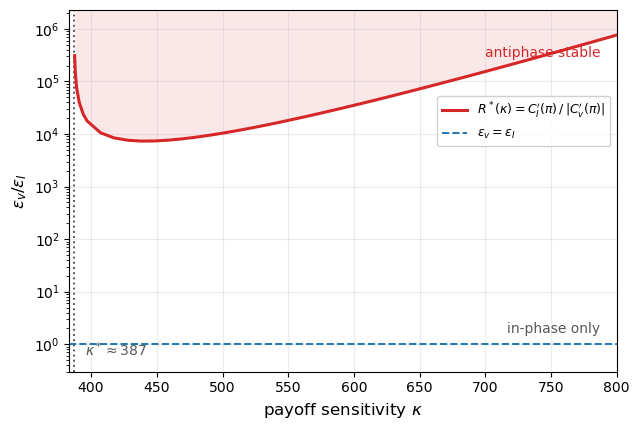

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.4))

ax.fill_between(k_fine, R_star, 1e12, color='tab:red', alpha=0.10, lw=0)
ax.plot(k_fine, R_star, color='tab:red', linewidth=2.2, zorder=3,
        label=r"$R^*(\kappa) = C_I'(\pi)\,/\,|C_v'(\pi)|$")
ax.axvline(kappa_star, color='0.35', linestyle=':', linewidth=1.4)
ax.axhline(1.0, color='tab:blue', linestyle='--', linewidth=1.4,
           label=r'$\epsilon_v = \epsilon_I$')

ax.set_yscale('log')
ax.set_xlim(k_fine.min() - 4, k_fine.max())
ax.set_ylim(0.3, max(1e6, 3 * R_star.max()))
ax.set_xlabel(r'payoff sensitivity $\kappa$', fontsize=12)
ax.set_ylabel(r'$\epsilon_v / \epsilon_I$', fontsize=12)

ax.text(0.97, 0.90, 'antiphase stable', transform=ax.transAxes,
        ha='right', va='top', fontsize=10, color='tab:red')
ax.text(0.97, 0.10, 'in-phase only', transform=ax.transAxes,
        ha='right', va='bottom', fontsize=10, color='0.35')
ax.annotate(rf'$\kappa^* \approx {kappa_star:.0f}$',
            xy=(kappa_star, 0.6), xytext=(8, 0),
            textcoords='offset points', fontsize=10, color='0.35')

ax.legend(loc='upper right', bbox_to_anchor=(1.0, 0.78),
          fontsize=9, framealpha=0.9)
ax.grid(True, which='major', alpha=0.25)
plt.tight_layout()
plt.savefig('threshold_ratio.pdf', bbox_inches='tight')
plt.savefig('threshold_ratio.png', dpi=200, bbox_inches='tight')
plt.show()